# ATM Withdrawal Forecasting Using a Simple RNN

This notebook uses the same transaction-level CSV format as the earlier Linear Regression and Random Forest example.

**Workflow**
1. Load transaction data.
2. Aggregate transactions by hour.
3. Create a continuous hourly series.
4. Scale the target using training data only.
5. Create 24-hour sequences to predict the next hour.
6. Train a SimpleRNN model.
7. Evaluate with MAE and RMSE.
8. Plot actual versus predicted hourly withdrawals.

> The data is synthetic and covers one month. The RNN is a teaching baseline; a small dataset may not be sufficient for reliable deep-learning performance.

If TensorFlow is not installed, run:
```python
%pip install pandas numpy matplotlib scikit-learn tensorflow
```


## 1. Import libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)


## 2. Load the transaction-level CSV

In [6]:
# Keep the CSV in the same folder as this notebook.
CSV_PATH = "atm_transactions.csv"

df = pd.read_csv("sample_atm_transactions.csv", parse_dates=["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)

print("Number of transactions:", len(df))
print("ATM IDs:", df["ATM_ID"].unique())
print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
display(df.head())


Number of transactions: 2474
ATM IDs: ['ATM_001']
Date range: 2026-01-01 01:10:00 to 2026-01-31 22:25:00


,Timestamp,ATM_ID,Withdrawal_Amount,Transaction_ID,ATM_Type,Day_of_Week,Is_Weekend
0,2026-01-01 01:10:00,ATM_001,5000,TXN00002,Bank ATM,Thursday,0
1,2026-01-01 01:38:00,ATM_001,500,TXN00001,Bank ATM,Thursday,0
2,2026-01-01 05:57:00,ATM_001,500,TXN00004,Bank ATM,Thursday,0
3,2026-01-01 05:59:00,ATM_001,2000,TXN00003,Bank ATM,Thursday,0
4,2026-01-01 07:46:00,ATM_001,1000,TXN00006,Bank ATM,Thursday,0


## 3. Aggregate transactions by hour

In [7]:
df["Hour_Timestamp"] = df["Timestamp"].dt.floor("h")

hourly = df.groupby("Hour_Timestamp").agg(
    Total_Withdrawal=("Withdrawal_Amount", "sum"),
    Transaction_Count=("Transaction_ID", "count"),
    Avg_Withdrawal=("Withdrawal_Amount", "mean")
)
hourly.head()

,Total_Withdrawal,Transaction_Count,Avg_Withdrawal
Hour_Timestamp,,,
2026-01-01 01:00:00,5500,2,2750.0
2026-01-01 05:00:00,2500,2,1250.0
2026-01-01 07:00:00,2000,2,1000.0
2026-01-01 08:00:00,6000,5,1200.0
2026-01-01 09:00:00,4000,4,1000.0


In [8]:

# Include every hour, including hours with no transactions.
all_hours = pd.date_range(
    start=df["Timestamp"].min().floor("h"),
    end=df["Timestamp"].max().floor("h"),
    freq="h"
)
all_hours

DatetimeIndex(['2026-01-01 01:00:00', '2026-01-01 02:00:00',
               '2026-01-01 03:00:00', '2026-01-01 04:00:00',
               '2026-01-01 05:00:00', '2026-01-01 06:00:00',
               '2026-01-01 07:00:00', '2026-01-01 08:00:00',
               '2026-01-01 09:00:00', '2026-01-01 10:00:00',
               ...
               '2026-01-31 13:00:00', '2026-01-31 14:00:00',
               '2026-01-31 15:00:00', '2026-01-31 16:00:00',
               '2026-01-31 17:00:00', '2026-01-31 18:00:00',
               '2026-01-31 19:00:00', '2026-01-31 20:00:00',
               '2026-01-31 21:00:00', '2026-01-31 22:00:00'],
              dtype='datetime64[ns]', length=742, freq='h')

In [9]:

hourly = hourly.reindex(all_hours, fill_value=0)
hourly.index.name = "Timestamp"
hourly = hourly.reset_index()
hourly.head()

,Timestamp,Total_Withdrawal,Transaction_Count,Avg_Withdrawal
0,2026-01-01 01:00:00,5500,2,2750.0
1,2026-01-01 02:00:00,0,0,0.0
2,2026-01-01 03:00:00,0,0,0.0
3,2026-01-01 04:00:00,0,0,0.0
4,2026-01-01 05:00:00,2500,2,1250.0


In [10]:
### SKIP

hourly["Avg_Withdrawal"] = hourly["Avg_Withdrawal"].fillna(0)
hourly["Hour"] = hourly["Timestamp"].dt.hour
hourly["Day_of_Week"] = hourly["Timestamp"].dt.day_name()
hourly["Is_Weekend"] = (hourly["Timestamp"].dt.dayofweek >= 5).astype(int)

display(hourly.head(10))
print("Number of hourly observations:", len(hourly))

hourly.to_csv("atm_hourly_aggregated_rnn.csv", index=False)


,Timestamp,Total_Withdrawal,Transaction_Count,Avg_Withdrawal,Hour,Day_of_Week,Is_Weekend
0,2026-01-01 01:00:00,5500,2,2750.0,1,Thursday,0
1,2026-01-01 02:00:00,0,0,0.0,2,Thursday,0
2,2026-01-01 03:00:00,0,0,0.0,3,Thursday,0
3,2026-01-01 04:00:00,0,0,0.0,4,Thursday,0
4,2026-01-01 05:00:00,2500,2,1250.0,5,Thursday,0
5,2026-01-01 06:00:00,0,0,0.0,6,Thursday,0
6,2026-01-01 07:00:00,2000,2,1000.0,7,Thursday,0
7,2026-01-01 08:00:00,6000,5,1200.0,8,Thursday,0
8,2026-01-01 09:00:00,4000,4,1000.0,9,Thursday,0
9,2026-01-01 10:00:00,2000,2,1000.0,10,Thursday,0


Number of hourly observations: 742


## 4. Chronological train-test split

We use the first 80% of hours for training and the final 20% for testing. The split happens **before scaling and sequence creation** so the scaler is fitted only on training data.

For this baseline, the only input feature is `Total_Withdrawal`.

In [11]:
values = hourly[["Total_Withdrawal"]].astype("float32").values

split_index = int(len(values) * 0.80)
train_values = values[:split_index]
test_values = values[split_index:]

print("Training hours:", len(train_values))
print("Testing hours:", len(test_values))
print("Test begins at:", hourly["Timestamp"].iloc[split_index])


Training hours: 593
Testing hours: 149
Test begins at: 2026-01-25 18:00:00


## 5. Scale the data using training data only

In [12]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_values)
# Transform test data with the already-fitted scaler; do not fit on test data.
test_scaled = scaler.transform(test_values)

print("Scaled training range:", train_scaled.min(), "to", train_scaled.max())


Scaled training range: 0.0 to 1.0


## 6. Create 24-hour sequences

Each sample contains 24 consecutive hourly withdrawal values. The target is the withdrawal value for the next hour.

Example: hours 1–24 → predict hour 25.

In [13]:
WINDOW_SIZE = 24

# Create training sequences only from the training portion.
X_train, y_train = [], []
for i in range(WINDOW_SIZE, len(train_scaled)):
    X_train.append(train_scaled[i-WINDOW_SIZE:i, 0])
    y_train.append(train_scaled[i, 0])


In [14]:
X_train[0]

array([0.11702128, 0.        , 0.        , 0.        , 0.05319149,
       0.        , 0.04255319, 0.12765957, 0.08510638, 0.04255319,
       0.20212765, 0.11702128, 0.20212765, 0.13829787, 0.17021276,
       0.14893617, 0.23404256, 0.4148936 , 0.393617  , 0.        ,
       0.25531915, 0.0106383 , 0.0212766 , 0.        ], dtype=float32)

In [15]:
y_train[0]

np.float32(0.0)

In [16]:
len(X_train)

569

In [17]:

#convert list to np array of float values
#reshape- A SimpleRNN expects a three-dimensional input array with this structure:
#(number_of_samples, time_steps, number_of_features)
# The -1 tells NumPy to calculate this dimension automatically from the total number of values and the other dimensions.
X_train = np.array(X_train, dtype=np.float32).reshape(-1, WINDOW_SIZE, 1)
y_train = np.array(y_train, dtype=np.float32)

# For the test period, use the previous 24 actual hours as context.
# This evaluates one-step-ahead forecasts, where each test prediction can
# use the observed withdrawals from earlier hours in the test period.
combined_scaled = np.vstack([train_scaled[-WINDOW_SIZE:], test_scaled])

X_test, y_test_scaled = [], []
for i in range(WINDOW_SIZE, len(combined_scaled)):
    X_test.append(combined_scaled[i-WINDOW_SIZE:i, 0])
    y_test_scaled.append(combined_scaled[i, 0])

X_test = np.array(X_test, dtype=np.float32).reshape(-1, WINDOW_SIZE, 1)
y_test_scaled = np.array(y_test_scaled, dtype=np.float32)

print("X_train shape:", X_train.shape)  # samples, 24 hours, 1 feature
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test_scaled.shape)


X_train shape: (569, 24, 1)
y_train shape: (569,)
X_test shape: (149, 24, 1)
y_test shape: (149,)


## 7. Build and train the SimpleRNN model

In [18]:
model = Sequential([
    Input(shape=(WINDOW_SIZE, 1)),
    SimpleRNN(32, activation="tanh"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=60,
    batch_size=16,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

model.summary()


Epoch 1/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0293 - val_loss: 0.0258
Epoch 2/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0228 - val_loss: 0.0250
Epoch 3/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0219 - val_loss: 0.0249
Epoch 4/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0211 - val_loss: 0.0242
Epoch 5/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0207 - val_loss: 0.0241
Epoch 6/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0205 - val_loss: 0.0241
Epoch 7/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0203 - val_loss: 0.0241
Epoch 8/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0202 - val_loss: 0.0241
Epoch 9/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0201 - val_loss: 0.0241
Epoch 10/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0201 - val_loss: 0.0242
Epoch 11/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0200 - val_loss: 0.0242
Epoch 12/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0199 - val_lo

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,365 (13.15 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,244 (8.77 KB)

## 8. Plot training and validation loss

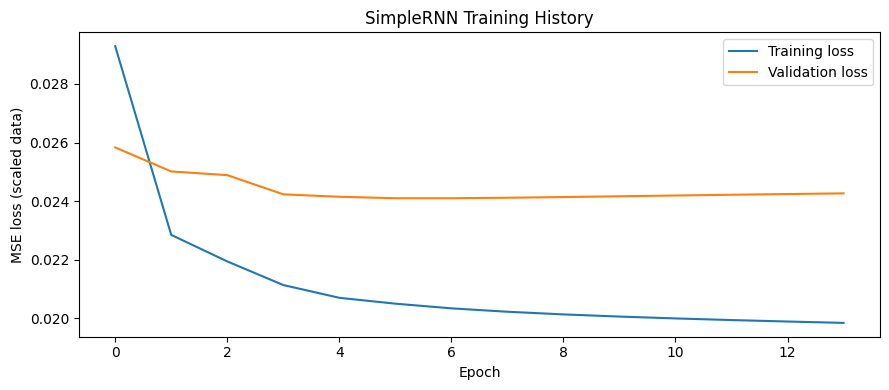

In [19]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("SimpleRNN Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (scaled data)")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Predict and evaluate

In [20]:
predicted_scaled = model.predict(X_test, verbose=0)

# Convert predictions and actual values back to withdrawal currency units.
predicted = scaler.inverse_transform(predicted_scaled).ravel()
actual = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).ravel()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"SimpleRNN MAE:  {mae:.2f}")
print(f"SimpleRNN RMSE: {rmse:.2f}")


SimpleRNN MAE:  5206.34
SimpleRNN RMSE: 7198.96


## 10. Plot actual versus predicted withdrawals

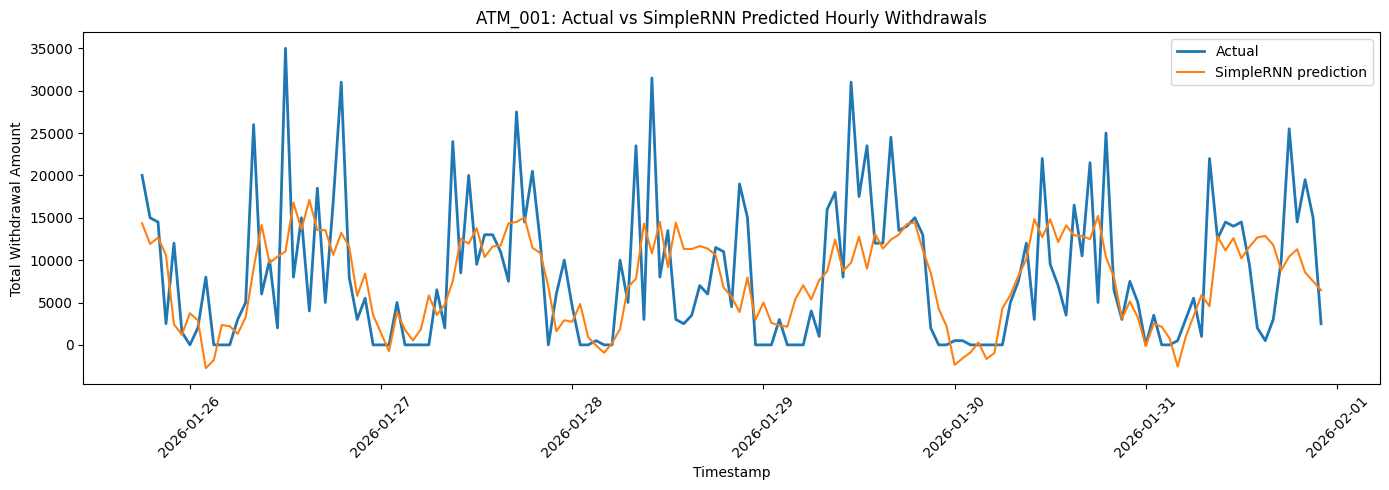

In [21]:
# These timestamps align with the test targets.
test_timestamps = hourly["Timestamp"].iloc[split_index:].reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(test_timestamps, actual, label="Actual", linewidth=2)
plt.plot(test_timestamps, predicted, label="SimpleRNN prediction", linewidth=1.5)
plt.title("ATM_001: Actual vs SimpleRNN Predicted Hourly Withdrawals")
plt.xlabel("Timestamp")
plt.ylabel("Total Withdrawal Amount")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 11. Save predictions and evaluation metrics

In [22]:
predictions_df = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual_Withdrawal": actual,
    "SimpleRNN_Prediction": predicted
})
display(predictions_df.head(10))
predictions_df.to_csv("atm_rnn_test_predictions.csv", index=False)

metrics_df = pd.DataFrame([{
    "Model": "SimpleRNN",
    "Input_Window_Hours": WINDOW_SIZE,
    "MAE": mae,
    "RMSE": rmse
}])
display(metrics_df.round(2))
metrics_df.to_csv("atm_rnn_evaluation_metrics.csv", index=False)


,Timestamp,Actual_Withdrawal,SimpleRNN_Prediction
0,2026-01-25 18:00:00,20000.0,14347.842773
1,2026-01-25 19:00:00,15000.0,11901.663086
2,2026-01-25 20:00:00,14500.0,12663.526367
3,2026-01-25 21:00:00,2500.0,10587.857422
4,2026-01-25 22:00:00,12000.0,2429.260010
5,2026-01-25 23:00:00,1500.0,1197.671387
6,2026-01-26 00:00:00,0.0,3732.647705
7,2026-01-26 01:00:00,2000.0,2913.860596
8,2026-01-26 02:00:00,8000.0,-2750.160156
9,2026-01-26 03:00:00,0.0,-1801.486206


,Model,Input_Window_Hours,MAE,RMSE
0,SimpleRNN,24,5206.34,7198.96


## Interpretation and limitations

- The model uses the previous 24 hours of total withdrawals to predict the next hour.
- The test evaluation is **one-step-ahead**: observed withdrawals from earlier test hours may be used as context for later test predictions.
- This differs from forecasting the entire final 20% recursively without seeing actual test-period values.
- The dataset is only one month long, so results may vary substantially by random seed and model settings.
- This model predicts withdrawal demand, not remaining cash balance or cash replenishment needs.
